# **PRAKTIKUM LANJUTAN P5-6**

---
---

**STUDI KASUS:**

SIMUTEH: Sistem Pemeriksaan Mutu Daun Teh Berbasis Citra untuk Kelompok Tani Teh Rakyat di Kabupaten Sukabumi

**Pertemuan 6 : Operasi Morfologi dan Komponen Terhubung**

# Bagian 3. Operasi Morfologi pada Citra Biner

---


**Tujuan:** memahami pengaruh setiap operasi morfologi dan structuring element
(SE), lalu memilih kombinasi yang membersihkan bercak awal tanpa menghapus bercak
kecil.

In [14]:
# Persiapan (Kode 1.1 + tepi_canny dari kode 1.3)
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-1032/notebook

import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/simuteh-1032/notebook


**Langkah 3.2 Citra Biner Awal**

---

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.997                   246               8           0.452
1  teh_021.png          0.997                   100               2           0.116
2  teh_011.png          0.998                   221               0               -


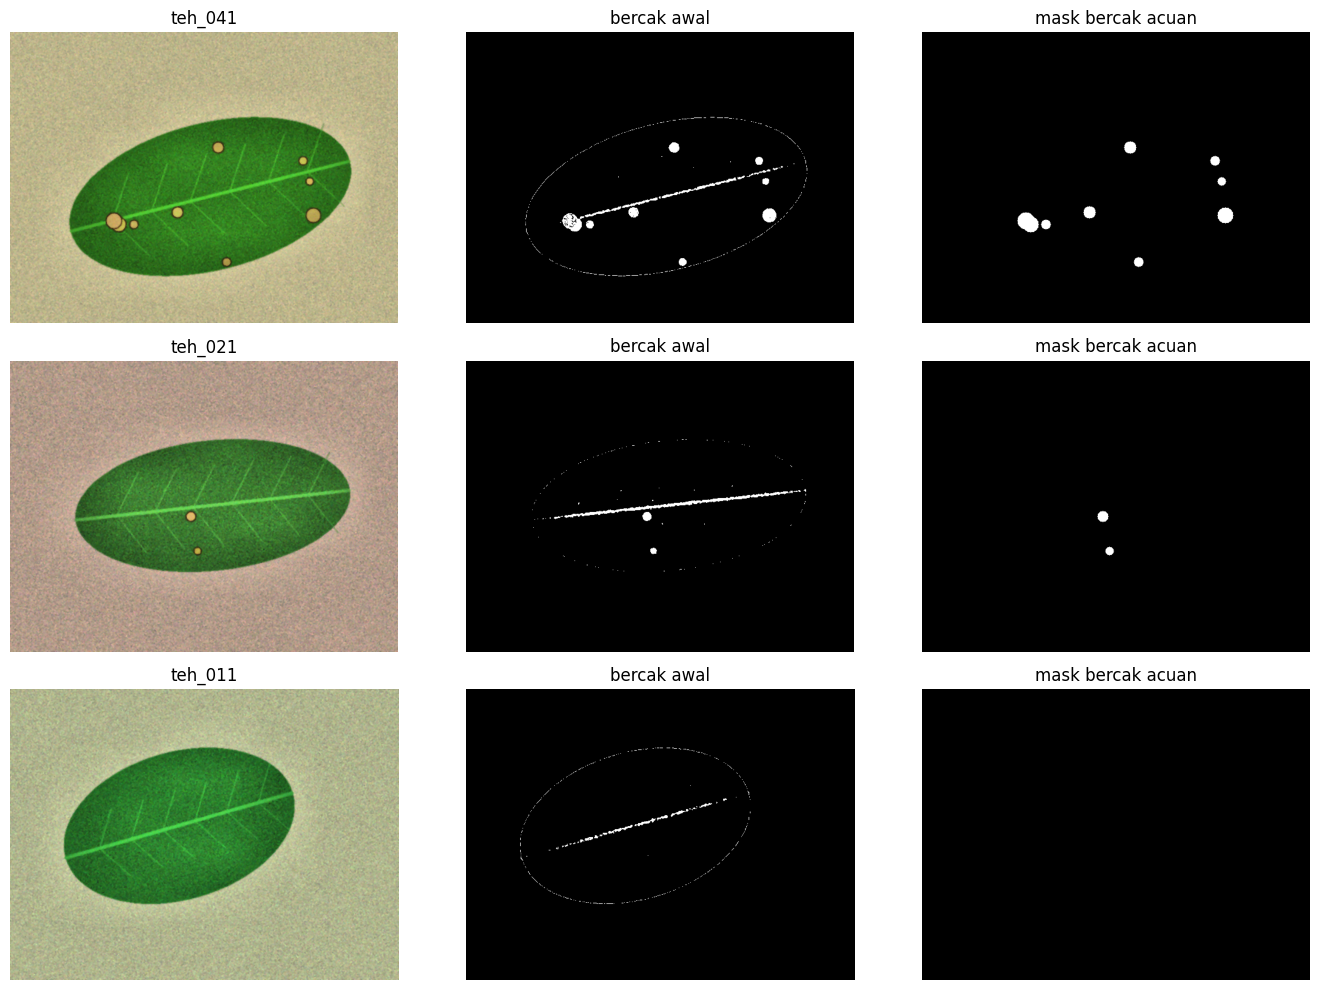

In [15]:
# Kode 3.1 Mask Daun Awal dan Bercak Awal
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:  # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra)
    b0 = bercak_awal(pra, m_daun, kanal=2, k=4.0)
    baris.append([
        nama,
        round(iou(m_daun, md), 3),
        jumlah_komponen(b0),
        jumlah_komponen(mb),
        round(iou(b0, mb), 3) if mb.any() else "-"
    ])
    panel += [pra, b0, mb]
    judul += [nama[:7], "bercak awal", "mask bercak acuan"]

print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal", "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))

**Langkah 3.3 Enam Operasi**

---

Terapkan erosi, dilasi, opening, closing, serta opening lalu
closing dengan SE elips 5 x 5 pada citra bercak ringan dan citra sehat.

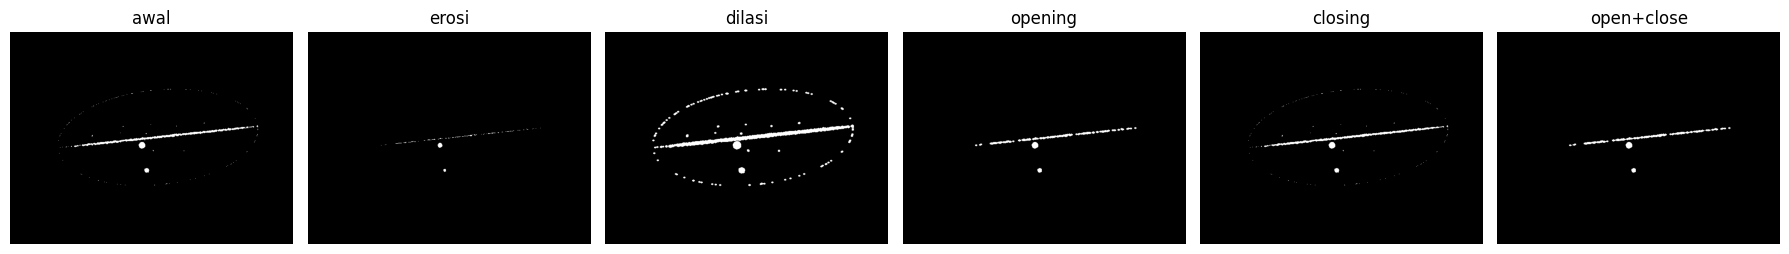

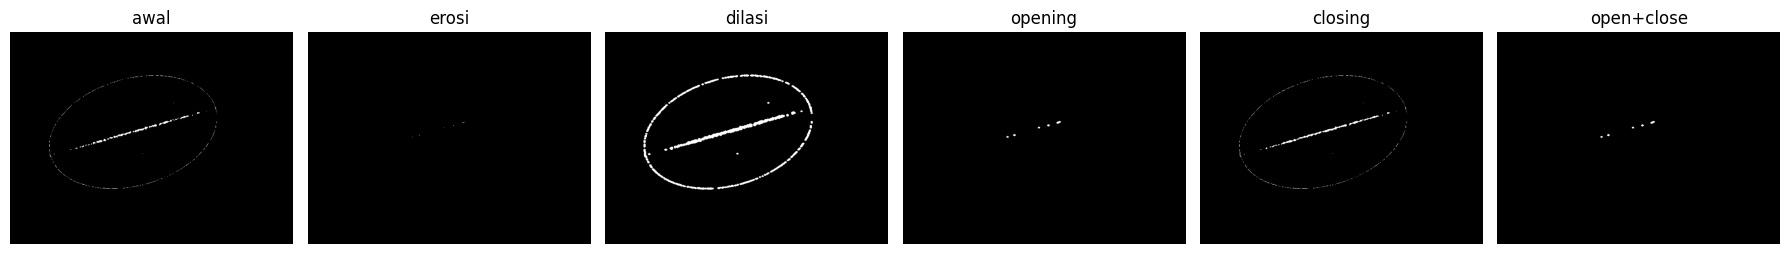

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       100    2148  0.116
1   teh_021.png       erosi        51     325  0.204
2   teh_021.png      dilasi        66    5683  0.071
3   teh_021.png     opening        19    1576  0.151
4   teh_021.png     closing        98    2195  0.114
5   teh_021.png  open+close         8    1614  0.147
6   teh_011.png        awal       221    1165      -
7   teh_011.png       erosi         6      11      -
8   teh_011.png      dilasi        36    6012      -
9   teh_011.png     opening         5     119      -
10  teh_011.png     closing       199    1286      -
11  teh_011.png  open+close         5     119      -


In [16]:
# Kode 3.2 Enam Operasi Morfologi
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {
        "awal": b,
        "erosi": cv2.erode(b, se),
        "dilasi": cv2.dilate(b, se),
        "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
        "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
        "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
    }

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra = praproses(img, PARAM)
    b0 = bercak_awal(pra, mask_daun_awal(pra))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([
            nama, nm, jumlah_komponen(m), int((m > 0).sum()),
            round(iou(m, mb), 3) if mb.any() else "-"
        ])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3))
    plt.show()

print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

**Langkah 3.4 Eksperimen Ambang dan SE**

---

Uji tiga nilai k pada bercak_awal, tiga bentuk
SE, dan tiga ukuran SE pada seluruh 60 citra.

In [17]:
# Kode 3.3 Eksperimen k, Bentuk SE, dan Ukuran SE
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([
                    d.kelas, k, nb, uk,
                    abs(jumlah_komponen(m) - n_acuan),
                    iou(m, mb) if mb.any() else np.nan
                ])

eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
piv_eks = eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas", values=["galat_jumlah", "IoU"]).round(2)
print(piv_eks)
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.62   0.17        14.05  14.85  17.50
          5       0.66   0.28         2.70   3.45   5.30
          7       0.73   0.40         1.70   2.20   2.05
  persegi 3       0.63   0.20         4.55   7.40   8.15
          5       0.69   0.33         3.25   2.95   3.55
          7       0.72   0.40         0.30   0.65   0.00
  silang  3       0.62   0.17        14.05  14.85  17.50
          5       0.66   0.26         5.25   6.35   7.45
          7       0.74   0.42         2.65   3.80   4.35
4 elips   3       0.66   0.30        14.55   9.95  12.85
          5       0.70   0.39         2.55   2.55   2.85
          7       0.72   0.49         0.40   0.45   0.20
  persegi 3       0.67   0.33         6.55   4.90   7.20
          5       0.71   0.45         1.00   1.45   1.05
          7       0.69   0.39  

**Langkah 3.5 Gradien Morfologi sebagai Tepi Daun**

---

Gradien morfologi (dilasi dikurangi
erosi) dari mask daun juga menghasilkan tepi. Bandingkan dengan Canny untuk batas daun
saja.

In [18]:
# Kode 3.4 Gradien Morfologi vs Canny untuk Batas Daun
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))  # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])

print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"]).groupby("kondisi").mean().round(3))

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.824     0.697
gelap                          0.973     0.686
kontras_rendah                 0.148     0.906
normal                         0.976     0.695
terang                         0.950     0.692


**Langkah 3.6**

---

Tampilkan elemen SE persegi, elips, dan silang berukuran
3, 5, dan 7 dengan cv2.getStructuringElement dalam satu panel. Gunakan panel ini
untuk menjelaskan hasil eksperimen pada Kode 3.3.

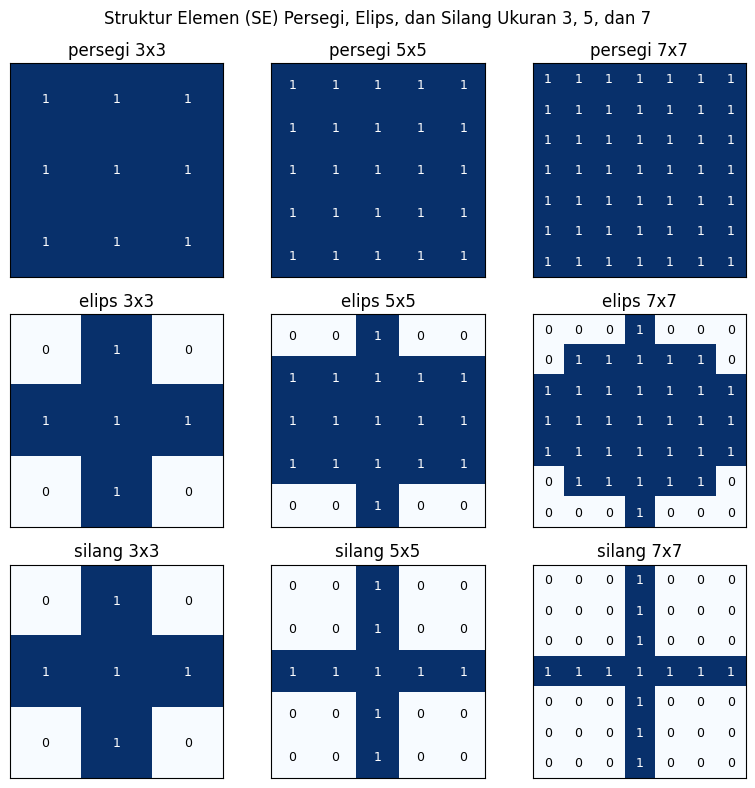

In [19]:
# Langkah 3.6 Visualisasi Panel Bentuk dan Ukuran SE
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for i, (nb, kb) in enumerate(bentuk.items()):
    for j, uk in enumerate([3, 5, 7]):
        mat = cv2.getStructuringElement(kb, (uk, uk))
        ax = axes[i, j]
        ax.imshow(mat, cmap="Blues", vmin=0, vmax=1)
        for r in range(uk):
            for c in range(uk):
                ax.text(c, r, str(mat[r, c]), ha="center", va="center",
                        color="white" if mat[r, c] else "black", fontsize=9)
        ax.set_title(f"{nb} {uk}x{uk}")
        ax.set_xticks([])
        ax.set_yticks([])

plt.suptitle("Struktur Elemen (SE) Persegi, Elips, dan Silang Ukuran 3, 5, dan 7", fontsize=12)
plt.tight_layout()
plt.show()

# Jawaban Pertanyaan Analisis Bagian 3

---

**P3.1:** Erosi dan opening menghapus bercak berlubang karena lubang 0 di tengah membuat SE 3×3 tidak pernah muat penuh, sedangkan dilasi awal pada closing menutup celah 2 px sehingga berisiko menggabungkan derau/tulang daun dengan bercak sejati.

**P3.2:** Konektivitas 8 lebih tepat karena tepi bercak melengkung sering terhubung diagonal; konektivitas 4 memecah satu bercak menjadi beberapa komponen (seperti Langkah 3.1a yang menghitung 4 komponen).

**P3.3:** Opening menghapus objek lebih kecil dari SE (derau 1–2 px, tepi daun tipis) lalu memulihkan ukuran bercak sejati, sedangkan closing memperbesar dan menyatukan derau. Potongan tulang daun bertahan pasca-opening bila lebarnya melebihi diameter SE 5×5.

**P3.4:** Kombinasi k = 4 dan SE Elips 5×5 (Tabel 3) dipilih karena menyeimbangkan penurunan galat jumlah (14,55→2,55 berat; 12,85→2,85 sehat) dan ketahanan bentuk bercak (IoU berat 0,70; ringan 0,39) tanpa pengikisan sudut Persegi 7×7. Baris Elips 3 dan Silang 3 identik di seluruh kolom karena susunan pikselnya sama pada kisi 3×3 (Gambar 6).

**P3.5:** Gradien morfologi (dilasi − erosi) bekerja langsung pada mask daun Otsu kanal S yang kontrasnya tegas di semua kondisi cahaya sehingga kontur daun selalu tertutup penuh, sedangkan Canny dibutuhkan untuk mencari batas internal di dalam daun tanpa mask awal.


# Bagian 4. Komponen Terhubung dan Pengukuran Bercak

---

**Tujuan:** melabeli setiap bercak, mengukur ukuran dan bentuknya dalam piksel dan
milimeter, lalu memakai ukuran bentuk untuk menyaring bercak palsu.

**Langkah 4.2 Label dan Ukur**

---

konektivitas 4: 20 komponen
konektivitas 8: 20 komponen

=== Tabel 10: Ukuran Setiap Bercak pada teh_041 ===
 label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek  cx  cy
     1      230     44.02         54.6       0.97         1.00 342 190
     2      135     25.84         41.0       1.01         1.00 483 211
     3       94     17.99         34.7       0.98         1.00 493 245
     4       26      4.98         18.5       0.96         1.87 433 244
     5       25      4.79         19.3       0.84         1.50 416 249
     6       22      4.21         15.7       1.13         1.25 406 251
     7        1      0.19          0.0       0.00         0.00 411 250
     8       61     11.68         33.3       0.69         2.95 387 255
     9       17      3.25         13.7       1.15         1.25 346 266
    10       31      5.93         20.5       0.93         1.89 328 270
    11       22      4.21         15.7       1.13         1.25 312 275
    12       63     12.06         48.3 

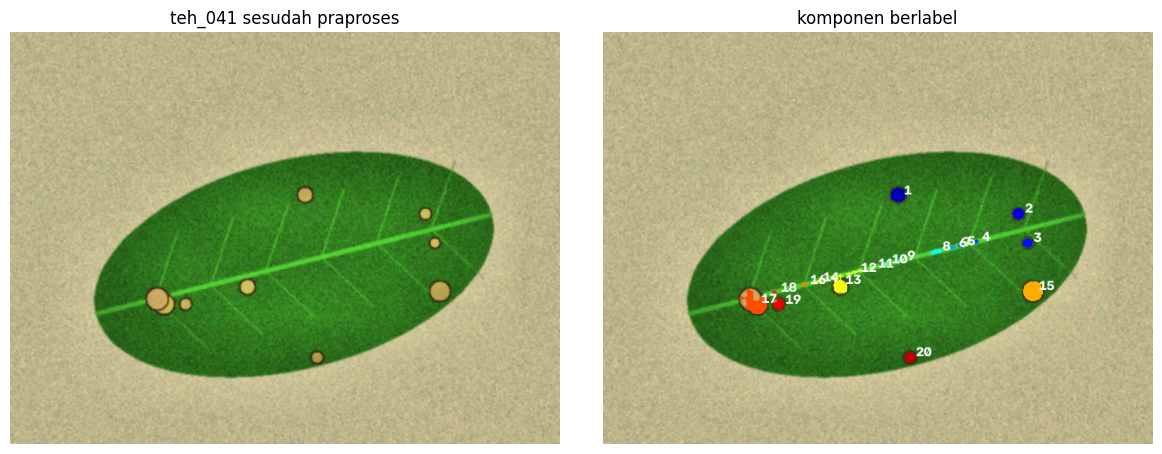

In [20]:
# Kode 4.1 Komponen Terhubung & Pengukuran
MM_PER_PX = 0.4375  # dari lembar hitung P2: Z=200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([
            i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1),
            round(kebulatan, 2), round(rasio, 2), int(cen[i][0]), int(cen[i][1])
        ])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
m_daun = mask_daun_awal(pra)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))

for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")

tabel_kom, lbl = ukur_komponen(bersih)
print("\n=== Tabel 10: Ukuran Setiap Bercak pada teh_041 ===")
print(tabel_kom.to_string(index=False))

# Tambahan bantu untuk analisis P4.4: perbandingan luas total vs mask acuan
luas_hasil = int((bersih > 0).sum())
luas_acuan = int((mb > 0).sum())
selisih_persen = (luas_hasil - luas_acuan) / luas_acuan * 100
print(f"\n[Info P4.4] Luas hasil: {luas_hasil} px | Luas acuan: {luas_acuan} px | Selisih: {selisih_persen:+.2f}%")

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)

tampil([pra, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))

**Langkah 4.3 Saring Bercak Palsu**

---

Uji empat aturan penyaringan berdasarkan luas,
kebulatan, dan rasio aspek pada seluruh 60 citra.

In [21]:
# Kode 4.2 Penyaringan Komponen Berdasarkan Ukuran dan Bentuk
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[
        (tabel_k.luas_px >= luas_min) &
        (tabel_k.kebulatan >= bulat_min) &
        (tabel_k.rasio_aspek <= rasio_maks)
    ]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {
    "tanpa saring": (0, 0, 99),
    "luas >= 20": (20, 0, 99),
    "luas + kebulatan": (20, 0.5, 99),
    "luas + kebulatan + rasio": (20, 0.5, 1.8)
}

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])

uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()

print("=== Rerata Galat Jumlah Bercak per Aturan dan Kelas ===")
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))

print("\n=== Jumlah Daun Sehat yang Masih Memiliki Bercak Palsu ===")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum())

=== Rerata Galat Jumlah Bercak per Aturan dan Kelas ===
kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           1.55    0.80   1.30
luas + kebulatan + rasio   1.05    0.35   0.60
luas >= 20                 1.90    2.00   2.35
tanpa saring               2.55    2.55   2.85

=== Jumlah Daun Sehat yang Masih Memiliki Bercak Palsu ===
aturan
luas + kebulatan            12
luas + kebulatan + rasio     9
luas >= 20                  12
tanpa saring                13
Name: palsu, dtype: int64


**Langkah 4.4 Dasar Ambang Penyaringan**

---

Untuk setiap komponen
hasil pembersihan pada 60 citra, tandai komponen "benar" bila lebih dari separuh pikselnya
berada di mask_bercak acuan, dan "palsu" bila tidak. Buat diagram sebar kebulatan
terhadap rasio aspek dengan warna berbeda untuk komponen benar dan palsu. Gunakan
diagram ini untuk menjustifikasi ambang luas_min, bulat_min, dan rasio_maks.

=== Ringkasan Statistik Komponen Benar vs Palsu ===
       luas_px                                                    kebulatan        ...             rasio_aspek                                          
         count    mean     std   min    25%    50%    75%     max     count  mean  ...   75%   max       count  mean   std  min   25%   50%   75%    max
status                                                                             ...                                                                  
benar    185.0  334.77  268.51  17.0  137.0  264.0  503.0  2136.0     185.0  0.92  ...  1.00  1.15       185.0  1.15  0.37  1.0  1.00  1.05  1.13   4.92
palsu    160.0  102.62  218.09   1.0   22.0   35.0   69.0  1882.0     160.0  0.74  ...  1.13  1.15       160.0  4.14  5.80  0.0  1.25  2.00  3.95  47.45

[2 rows x 24 columns]


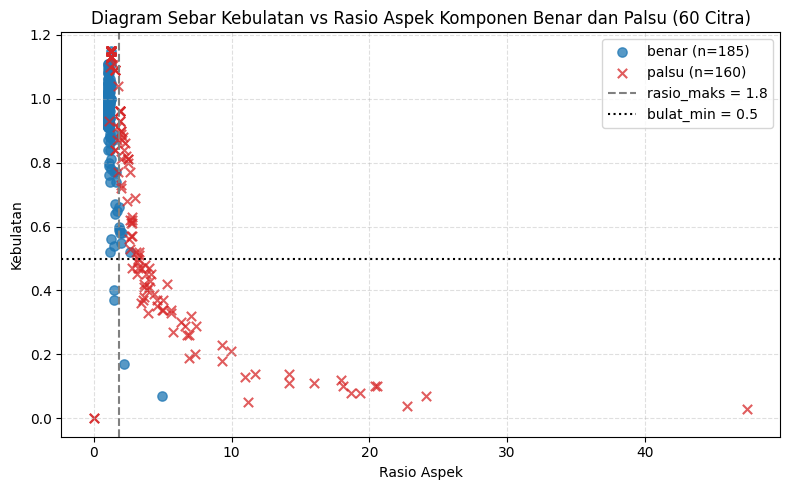

In [22]:
# Kode Langkah 4.4 Diagram Sebar Komponen Benar vs Palsu
data_kom = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    tabel_k, lbl = ukur_komponen(bersih)
    acuan_bin = mb > 0
    for _, r in tabel_k.iterrows():
        mask_i = (lbl == int(r.label))
        proporsi_acuan = (mask_i & acuan_bin).sum() / max(mask_i.sum(), 1)
        status = "benar" if proporsi_acuan > 0.5 else "palsu"
        data_kom.append([d.kelas, status, r.luas_px, r.kebulatan, r.rasio_aspek])

df_kom = pd.DataFrame(data_kom, columns=["kelas", "status", "luas_px", "kebulatan", "rasio_aspek"])
print("=== Ringkasan Statistik Komponen Benar vs Palsu ===")
print(df_kom.groupby("status")[["luas_px", "kebulatan", "rasio_aspek"]].describe().round(2))

plt.figure(figsize=(8, 5))
for st, warna_titik, marker in [("benar", "#1f77b4", "o"), ("palsu", "#d62728", "x")]:
    sub = df_kom[df_kom["status"] == st]
    plt.scatter(sub["rasio_aspek"], sub["kebulatan"], label=f"{st} (n={len(sub)})",
                c=warna_titik, marker=marker, alpha=0.75, s=45)

plt.axvline(1.8, color="gray", linestyle="--", label="rasio_maks = 1.8")
plt.axhline(0.5, color="black", linestyle=":", label="bulat_min = 0.5")
plt.xlabel("Rasio Aspek")
plt.ylabel("Kebulatan")
plt.title("Diagram Sebar Kebulatan vs Rasio Aspek Komponen Benar dan Palsu (60 Citra)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Jawaban Pertanyaan Analisis Bagian 4

---

**P4.1:** Kebulatan diskrit dan nilai >1 pada OpenCV:

1.	Bercak 3×3 memiliki kebulatan 0,79 (π/4) dibanding garis 1×6 (0,38); nilainya <1,0 karena sudut siku-siku persegi memperpanjang keliling dibanding lingkaran ideal.
2. Pada komponen sangat kecil (1–4 px), cv2.findContours menghubungkan pusat piksel sehingga keliling poligon lebih pendek daripada tepi luar piksel dan membuat 4πA/K² melampaui 1,0.

**P4.2:** Asumsi skala 0,4375 mm/piksel dan perubahan jarak kamera:
1. Konversi ini mengasumsikan kamera tegak lurus pada Z = 200 mm, fokus lensa tetap, daun datar sejajar sensor, dan lebar citra kerja 640 piksel.
2. Jika dipotret dari 30 cm (300 mm), dimensi objek menyusut 200/300 = 2/3 sehingga luas terukur menyusut menjadi (2/3)² = 4/9 ≈ 44,4% (turun 55,6%); di lapangan SIMUTEH memakai nampan/penanda kalibrasi fisik standar untuk menghitung ulang skala mm/piksel.

**P4.3:** Aturan gabungan luas + kebulatan + rasio (Tabel 5, Gambar 8) paling efektif menekan galat daun sehat (2,85→0,60) dan daun sehat berbercak palsu (13→9 citra, total luas sisa <0,1%), namun rasio_maks ≤ 1,8 berisiko membuang dua bercak sejati yang menyatu lonjong atau memanjang mengikuti tulang daun.

**P4.4:** Pada teh_041.png, luas bercak terdeteksi 2.199 px berselisih -19,74% (-541 px) dibanding mask acuan (2.740 px) akibat: (1) tepi luar bercak bergradasi redup gagal melewati ambang global median + 4×MAD; (2) median 3×3 mengikis piksel tepi; dan (3) opening-closing meratakan kontur tepi bercak.


# Bagian 5. Integrasi: Modul Analisis Bercak SIMUTEH

---

**Tujuan:** menggabungkan seluruh temuan Pertemuan 5 dan 6 menjadi modul
bercak.py yang menerima citra hasil praproses dan mengeluarkan jumlah bercak, persen
bercak, dan kelas mutu, lalu mengevaluasinya pada seluruh dataset.

**Langkah 5.1 Kerjakan Sendiri**


---



In [23]:
# Langkah 5.1 Lengkapi Modul Membuat src/bercak.py
%%writefile ../src/bercak.py
"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""
import json
import cv2
import numpy as np
from utils_tepi import mask_daun_awal, bercak_awal

PARAM_BERCAK = {
    "kanal": 2,             # kanal terpilih (2 = R)
    "k": 4.0,               # ambang median + k x MAD
    "se_bentuk": "elips",   # "elips", "persegi", "silang"
    "se_open": 5,           # ukuran SE opening (0 = tidak dipakai)
    "se_close": 5,          # ukuran SE closing (0 = tidak dipakai)
    "luas_min": 20,         # piksel
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,    # persen bercak minimum kelas Ringan
    "batas_berat": 2.0,     # persen bercak minimum kelas Berat
    "mm_per_px": 0.4375,
}

BENTUK = {
    "elips": cv2.MORPH_ELLIPSE,
    "persegi": cv2.MORPH_RECT,
    "silang": cv2.MORPH_CROSS,
}

def se(p, uk):
    return cv2.getStructuringElement(BENTUK[p["se_bentuk"]], (uk, uk))

def bersihkan(biner, p):
    """Opening membuang titik derau dan potongan tipis; closing menutup celah."""
    # TODO 1: bila p["se_open"] > 0, lakukan opening dengan se(p, p["se_open"])
    if p["se_open"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_OPEN, se(p, p["se_open"]))
    # TODO 2: bila p["se_close"] > 0, lakukan closing dengan se(p, p["se_close"])
    if p["se_close"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, se(p, p["se_close"]))
    return biner

def ukur_dan_saring(biner, p):
    """Mengembalikan mask bercak tersaring dan daftar ukuran setiap bercak."""
    # TODO 3: label komponen terhubung (konektivitas 8) dengan cv2.connectedComponentsWithStats
    n, lbl, st, cen = cv2.connectedComponentsWithStats((biner > 0).astype(np.uint8), connectivity=8)
    keluar, daftar = np.zeros_like(biner, dtype=np.uint8), []
    mm_per_px = p.get("mm_per_px", 0.4375)

    for i in range(1, n):
        # TODO 4: hitung luas, keliling (cv2.arcLength), kebulatan, dan rasio aspek (cv2.minAreaRect)
        komp_mask = (lbl == i).astype(np.uint8)
        kontur, _ = cv2.findContours(komp_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        if not kontur:
            continue
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = float(cv2.arcLength(kontur[0], True))
        kebulatan = 0.0 if keliling == 0 else float(4 * np.pi * A / (keliling ** 2))
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = float(max(w, h) / max(min(w, h), 1))

        # TODO 5: simpan ke mask keluar hanya komponen yang memenuhi luas_min, bulat_min, dan rasio_maks
        if A >= p["luas_min"] and kebulatan >= p["bulat_min"] and rasio <= p["rasio_maks"]:
            keluar[lbl == i] = 255
            daftar.append({
                "label": len(daftar) + 1,
                "luas_px": A,
                "luas_mm2": round(A * (mm_per_px ** 2), 2),
                "keliling_px": round(keliling, 1),
                "kebulatan": round(kebulatan, 2),
                "rasio_aspek": round(rasio, 2),
                "cx": int(cen[i][0]),
                "cy": int(cen[i][1]),
            })
    return keluar, daftar

def analisis_daun(img_praproses, p=None):
    """Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis."""
    p = {**PARAM_BERCAK, **(p or {})}
    m_daun = mask_daun_awal(img_praproses)
    biner = bercak_awal(img_praproses, m_daun, kanal=p["kanal"], k=p["k"])
    m_bercak, daftar = ukur_dan_saring(bersihkan(biner, p), p)

    # TODO 6: hitung persen bercak = luas bercak / luas daun x 100
    luas_daun = int((m_daun > 0).sum())
    luas_bercak = int((m_bercak > 0).sum())
    persen = 0.0 if luas_daun == 0 else (luas_bercak / luas_daun) * 100.0

    # TODO 7: tentukan kelas dengan batas_ringan dan batas_berat
    if persen >= p["batas_berat"]:
        kelas = "Bercak Berat"
    elif persen >= p["batas_ringan"]:
        kelas = "Bercak Ringan"
    else:
        kelas = "Sehat"

    return {
        "mask_daun": m_daun,
        "mask_bercak": m_bercak,
        "jumlah_bercak": len(daftar),
        "persen_bercak": round(float(persen), 3),
        "kelas": kelas,
        "bercak": daftar,
    }

def simpan_param(p, path="../hasil/param_bercak.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)

Overwriting ../src/bercak.py


**Langkah 5.2 Evaluasi Menyeluruh**

---

Tentukan parameter PB dari temuan Anda (kosong
berarti memakai nilai bawaan), lalu evaluasi pada 60 citra.

Galat absolut rerata persen bercak: 0.583
Korelasi persen prediksi vs acuan : 0.955
Akurasi kelas                     : 0.9

=== Matriks Kekeliruan (Confusion Matrix) ===
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             18              2      0
Bercak Ringan             0             16      4
Sehat                     0              0     20

=== Akurasi per Kondisi Cahaya ===
kondisi
bayangan          0.92
gelap             1.00
kontras_rendah    0.75
normal            0.83
terang            1.00
Name: benar, dtype: float64


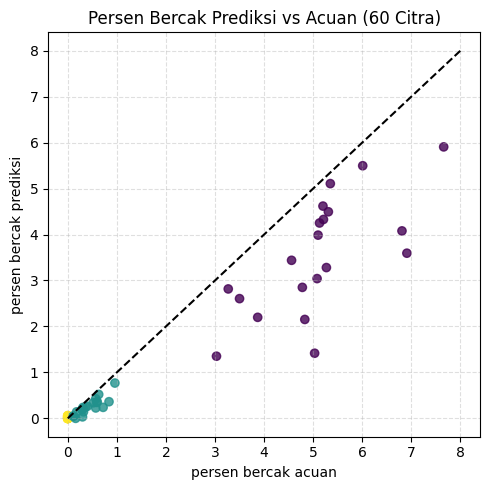

In [24]:
# Kode 5.2 Evaluasi Menyeluruh 60 Citra
import importlib, bercak
importlib.reload(bercak)

PB = {}  # ubah parameter di sini bila hasil eksperimen Bagian 3-4 Anda menunjukkan nilai lebih optimal
bercak.simpan_param(PB)

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([
        d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak,
        h["persen_bercak"], jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]
    ])

ev = pd.DataFrame(baris, columns=[
    "nama", "kelas", "kondisi", "persen_acuan",
    "persen_prediksi", "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"
])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas                     :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))

print("\n=== Matriks Kekeliruan (Confusion Matrix) ===")
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))

print("\n=== Akurasi per Kondisi Cahaya ===")
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))

plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes, alpha=0.8)
plt.plot([0, 8], [0, 8], "k--")
plt.xlabel("persen bercak acuan")
plt.ylabel("persen bercak prediksi")
plt.title("Persen Bercak Prediksi vs Acuan (60 Citra)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

**Langkah 5.3 Analisis Kesalahan**

---

Tampilkan setiap citra yang salah
kelas: citra hasil praproses, mask bercak hasil, dan mask bercak acuan berdampingan.
Tuliskan penyebab kesalahan untuk setiap citra.

Jumlah citra salah kelas: 6 dari 60 citra
       nama        kondisi   kelas_acuan kelas_prediksi  persen_acuan  persen_prediksi  jumlah_acuan  jumlah_prediksi
teh_025.png       bayangan Bercak Ringan          Sehat          0.11            0.046             1                1
teh_031.png         normal Bercak Ringan          Sehat          0.30            0.032             1                1
teh_034.png kontras_rendah Bercak Ringan          Sehat          0.16            0.000             1                0
teh_039.png kontras_rendah Bercak Ringan          Sehat          0.12            0.053             1                1
teh_041.png         normal  Bercak Berat  Bercak Ringan          3.03            1.352             8               10
teh_054.png kontras_rendah  Bercak Berat  Bercak Ringan          5.03            1.417             5                4


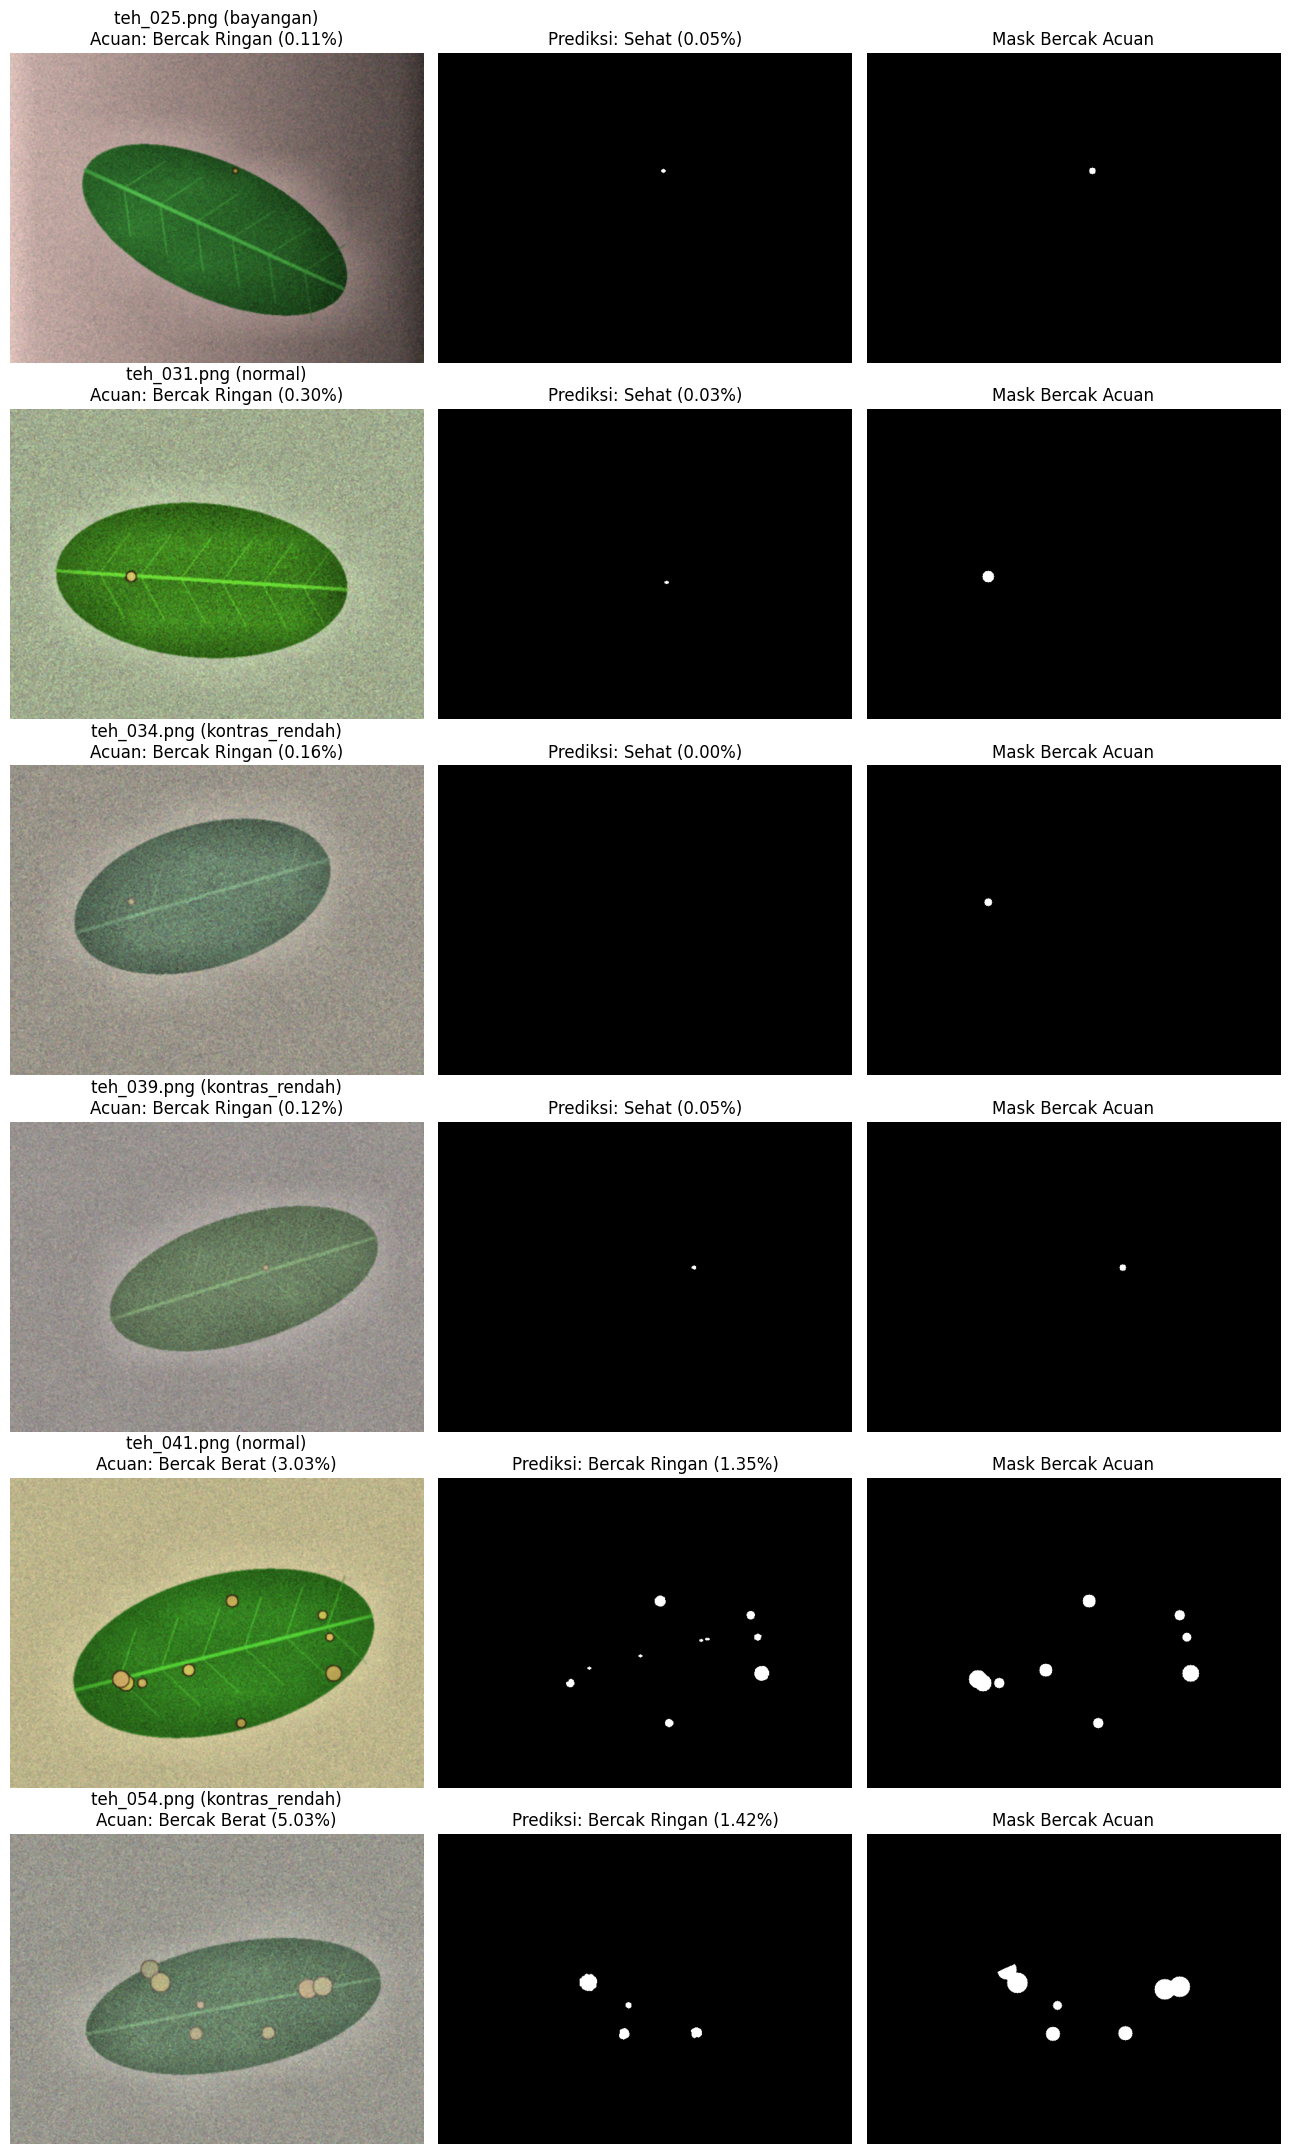

In [25]:
# Kode 5.3 Analisis Kesalahan Klasifikasi
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]
print(f"Jumlah citra salah kelas: {len(salah)} dari {len(ev)} citra")

if len(salah) > 0:
    print(salah[[
        "nama", "kondisi", "kelas_acuan", "kelas_prediksi",
        "persen_acuan", "persen_prediksi", "jumlah_acuan", "jumlah_prediksi"
    ]].to_string(index=False))

    panel_salah, judul_salah = [], []
    for _, r in salah.iterrows():
        img, md, mb = muat(r.nama)
        pra = praproses(img, PARAM)
        h = bercak.analisis_daun(pra, PB)
        panel_salah += [pra, h["mask_bercak"], mb]
        judul_salah += [
            f"{r.nama} ({r.kondisi})\nAcuan: {r.kelas_acuan} ({r.persen_acuan:.2f}%)",
            f"Prediksi: {r.kelas_prediksi} ({r.persen_prediksi:.2f}%)",
            "Mask Bercak Acuan"
        ]
    tampil(panel_salah, judul_salah, baris=len(salah), ukuran=(13, 3.6 * len(salah)))
else:
    print("Tidak ada citra yang salah kelas (akurasi 100%).")

**Langkah 5.4 Justifikasi Parameter**

---


# Jawaban Pertanyaan Analisis Bagian 5

---

**P5.1:** Modul src/bercak.py mencatat galat absolut rerata 0,583%, korelasi 0,955, akurasi kelas 90,0% (54/60 citra), dan 0 false positive pada daun sehat (Tabel 6, Gambar 9). Menurut Langkah 5.3 (Gambar 10), 6 citra salah kelas bergeser satu tingkat ke bawah:

1.	Empat Bercak Ringan → Sehat: teh_025.png (0,11%→0,05%), teh_031.png (0,30%→0,03%), teh_034.png (0,16%→0,00%), dan teh_039.png (0,12%→0,05%), akibat luas acuan di dekat ambang 0,1% menyusut di bawah ambang MAD dan opening 5×5 pada kondisi redup/kontras rendah.
2.	Dua Bercak Berat → Bercak Ringan: teh_041.png (3,03%→1,35%) dan teh_054.png (5,03%→1,42%), akibat bercak besar menyatu lonjong (kebulatan < 0,5 atau rasio_aspek > 1,8) terbuang filter bentuk serta gagal deteksi bercak samar pada kontras rendah.

**P5.2:** Penetapan batas kelas 0,1% dan 2,0% dari seluruh 60 citra label.csv memicu kebocoran data (data leakage) karena parameter disetel menggunakan data uji sehingga akurasi terlalu optimistis; pada P11 dataset wajib dipisah menjadi train, validation, dan test.

**P5.3:** Kondisi kontras_rendah mencatat akurasi terendah 0,75 (9/12 tepat; 3 dari 6 kesalahan), diikuti normal (0,83), karena rendahnya kontras mempersempit beda intensitas kanal R terhadap ambang global median + 4,0×MAD; pada Pertemuan 7 hal ini diperbaiki dengan ambang adaptif lokal, Otsu CIELAB (a*/b*), dan watershed.

**P5.4:** Bagi petani, false negative lebih merugikan karena memicu penularan spora cacar daun ke satu blok kebun, sedangkan false positive hanya memicu verifikasi ulang. Menurunkan k (misal 3,5) mengurangi false negative namun menaikkan false positive; sesuai prinsip amanah, SIMUTEH menampilkan overlay mask bercak berlabel dan persentase bercak untuk verifikasi visual petugas.

**P5.5:** Aturan bulat_min ≥ 0,5 dan rasio_maks ≤ 1,8 optimal pada dataset sintetis melingkar, namun berisiko gagal pada foto lapangan dengan bercak bergerigi atau menyatu mengikuti tulang daun; validasi dilakukan memakai foto lapangan beranotasi manual dan fitur warna/tekstur pada P9–P11.
